In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('data.csv')
df.head()

,student_id,name,gender,age,department,math_marks,physics_marks,chemistry_marks,exam_date,city,email
0,1,Rahim,Male,20,CSE,85,78.0,92.0,2025-01-15,Dhaka,rahim@example.com
1,2,Karim,male,22,CSE,76,81.0,88.0,15/01/2025,dhaka,karim@example.com
2,3,Nusrat,FEMALE,19,EEE,91,89.0,95.0,2025/01/16,Chattogram,nusrat@example.com
3,4,Sadia,Female,20,BBA,67,72.0,70.0,16-01-2025,Rajshahi,sadia@example.com
4,5,Imran,M,22,CSE,58,64.0,61.0,2025-01-17,Khulna,imran@example.com


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       50 non-null     int64  
 1   name             50 non-null     str    
 2   gender           49 non-null     str    
 3   age              48 non-null     str    
 4   department       49 non-null     str    
 5   math_marks       49 non-null     str    
 6   physics_marks    49 non-null     float64
 7   chemistry_marks  49 non-null     float64
 8   exam_date        49 non-null     str    
 9   city             49 non-null     str    
 10  email            49 non-null     str    
dtypes: float64(2), int64(1), str(8)
memory usage: 6.9 KB


In [5]:
df.describe()

,student_id,physics_marks,chemistry_marks
count,50.000000,49.000000,49.000000
mean,23.100000,77.428571,87.204082
std,14.958787,17.967563,62.903689
min,1.000000,0.000000,0.000000
25%,10.250000,74.000000,73.000000
50%,22.500000,80.000000,84.000000
75%,34.750000,89.000000,90.000000
max,50.000000,98.000000,500.000000


## Type Conversion

In [6]:
# invalid data thakle astype hobe na 
# df["math_marks"] = df['math_marks'].astype('float64') 

df['math_marks'] = pd.to_numeric(df['math_marks'], errors='coerce') 
df['physics_marks'] = pd.to_numeric(df['physics_marks'], errors='coerce') 
df['chemistry_marks'] = pd.to_numeric(df['chemistry_marks'], errors='coerce') 

df['age'] = pd.to_numeric(df['age'], errors='coerce')

df['exam_date'] = pd.to_datetime(df['exam_date'], errors='coerce')



## Remove Duplicate

In [7]:
df.duplicated().sum()

np.int64(2)

In [8]:
# When full row is duplicated, then drop it
df[df.duplicated(keep=False)].sort_values(by=['name'])
df.drop_duplicates(inplace=True)

C:\Users\offic\AppData\Local\Temp\ipykernel_16876\1438704582.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [9]:
# When only some columns are duplicated, then drop it
df[df.duplicated(subset=['name','student_id'], keep=False)].sort_values(by='name')
df.drop_duplicates(subset=['name','student_id'], inplace=True)

C:\Users\offic\AppData\Local\Temp\ipykernel_16876\349837381.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=['name','student_id'], inplace=True)


## Handling Null Values

In [10]:
# Step 1: Drop rows যখন সব Column-এর Value Null
df.dropna(how='all', inplace=True)

# Step 2: Drop rows যখন Important Column-এর Value Null
df.dropna(subset=['name', 'student_id', 'email'], inplace=True)

# Step 3: Check remaining missing values
df.isnull().sum()

C:\Users\offic\AppData\Local\Temp\ipykernel_16876\3258843016.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(how='all', inplace=True)
C:\Users\offic\AppData\Local\Temp\ipykernel_16876\3258843016.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['name', 'student_id', 'email'], inplace=True)


student_id         0
name               0
gender             1
age                3
department         1
math_marks         2
physics_marks      1
chemistry_marks    1
exam_date          5
city               1
email              0
dtype: int64

In [11]:
df[df.isnull().any(axis=1)]

,student_id,name,gender,age,department,math_marks,physics_marks,chemistry_marks,exam_date,city,email
1,2,Karim,male,22.0,CSE,76.0,81.0,88.0,NaT,dhaka,karim@example.com
2,3,Nusrat,FEMALE,19.0,EEE,91.0,89.0,95.0,NaT,Chattogram,nusrat@example.com
3,4,Sadia,Female,20.0,BBA,67.0,72.0,70.0,NaT,Rajshahi,sadia@example.com
7,8,Fahim,male,NaN,BBA,45.0,52.0,49.0,2025-01-18,Barishal,fahim@example.com
8,9,Ayesha,Female,21.0,CSE,82.0,NaN,87.0,2025-01-19,Dhaka,ayesha@example.com
9,10,Sakib,Male,20.0,EEE,NaN,74.0,79.0,2025-01-19,Cumilla,sakib@example.com
10,11,Rafi,NaN,23.0,CSE,71.0,69.0,NaN,2025-01-20,Dhaka,rafi@example.com
11,12,Tania,Female,20.0,NaN,89.0,91.0,90.0,2025-01-20,Sylhet,tania@example.com
12,13,Hasan,Male,21.0,CSE,100.0,98.0,99.0,NaT,Dhaka,hasan@example.com
13,14,Nabila,Female,19.0,EEE,77.0,83.0,80.0,2025-01-21,NaN,nabila@example.com


In [12]:
df['exam_date'] = df['exam_date'].bfill()

In [13]:
# Filling date null values 
df[df['exam_date'].isnull()] 
# df['exam_date'] = df['exam_date'].ffill()
df['exam_date'] = df['exam_date'].bfill()
df.isnull().sum()

student_id         0
name               0
gender             1
age                3
department         1
math_marks         2
physics_marks      1
chemistry_marks    1
exam_date          0
city               1
email              0
dtype: int64

In [14]:
# Fill city null values 
df[df['city'].isnull()] 
df['city'] = df['city'].fillna('Unknown')
df.isnull().sum()

student_id         0
name               0
gender             1
age                3
department         1
math_marks         2
physics_marks      1
chemistry_marks    1
exam_date          0
city               0
email              0
dtype: int64

In [15]:
# Fill age null values
df[df['age'].isnull()]
df['age'] = df['age'].fillna(df['age'].mean())
df.isnull().sum()

student_id         0
name               0
gender             1
age                0
department         1
math_marks         2
physics_marks      1
chemistry_marks    1
exam_date          0
city               0
email              0
dtype: int64

In [16]:
# fill gender null values
df[df['gender'].isnull()]
df['gender'].value_counts()
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df.isnull().sum()

student_id         0
name               0
gender             0
age                0
department         1
math_marks         2
physics_marks      1
chemistry_marks    1
exam_date          0
city               0
email              0
dtype: int64

In [17]:
# fill department null values
df[df['department'].isnull()]
df['department'] = df['department'].fillna(df['department'].mode()[0])
df.isnull().sum()


student_id         0
name               0
gender             0
age                0
department         0
math_marks         2
physics_marks      1
chemistry_marks    1
exam_date          0
city               0
email              0
dtype: int64

In [18]:
# fill marks null values
df['math_marks'] = df['math_marks'].fillna(df['math_marks'].mean())

df['physics_marks'] = df['physics_marks'].fillna(df['physics_marks'].mean())

# df['chemistry_marks'] = df['chemistry_marks'].fillna(df['chemistry_marks'].mean())

gender_mean = df.groupby('gender')['chemistry_marks'].mean()
df['chemistry_marks'] = df['chemistry_marks'].fillna(df['gender'].map(gender_mean))

df.isnull().sum()



student_id         0
name               0
gender             0
age                0
department         0
math_marks         0
physics_marks      0
chemistry_marks    0
exam_date          0
city               0
email              0
dtype: int64

## Inconsistent Categorical Values

In [19]:
# Clean city names
df['city'].unique()
df['city'] = df['city'].str.title().str.strip()

city_mapping = {
    'Dk': 'Dhaka',
}
df['city'] = df['city'].replace(city_mapping) # key na thakle ager value i thakbe
df['city'].unique()


<ArrowStringArray>
[     'Dhaka', 'Chattogram',   'Rajshahi',     'Khulna',     'Sylhet',
   'Barishal',    'Cumilla',    'Unknown', 'Chittagong']
Length: 9, dtype: str

In [20]:
# Clean gender names
df['gender'].unique()
df['gender'] = df['gender'].str.title().str.strip()
df['gender'].unique()

gender_mapping = {
    'M': 'Male',
    'F': 'Female',
    'Male': 'Male',
    'Female': 'Female',
}

df['gender'] = df['gender'].map(gender_mapping) # key na thakle NaN hobe
df['gender'].unique()


<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [21]:
df[~df['age'].between(0, 100) ]
df['age'] = df['age'].where( 
        df['age'].between(0, 100) , 
        other=df['age'].mode()[0]
    )
# df

In [22]:
df

,student_id,name,gender,age,department,math_marks,physics_marks,chemistry_marks,exam_date,city,email
0,1,Rahim,Male,20.0,CSE,85.000000,78.000000,92.000000,2025-01-15,Dhaka,rahim@example.com
1,2,Karim,Male,22.0,CSE,76.000000,81.000000,88.000000,2025-01-17,Dhaka,karim@example.com
2,3,Nusrat,Female,19.0,EEE,91.000000,89.000000,95.000000,2025-01-17,Chattogram,nusrat@example.com
3,4,Sadia,Female,20.0,BBA,67.000000,72.000000,70.000000,2025-01-17,Rajshahi,sadia@example.com
4,5,Imran,Male,22.0,CSE,58.000000,64.000000,61.000000,2025-01-17,Khulna,imran@example.com
5,6,Tanvir,Male,20.0,CSE,88.000000,90.000000,86.000000,2025-01-17,Dhaka,tanvir@example.com
6,7,Mim,Female,19.0,EEE,94.000000,96.000000,93.000000,2025-01-18,Sylhet,mim@example.com
7,8,Fahim,Male,27.0,BBA,45.000000,52.000000,49.000000,2025-01-18,Barishal,fahim@example.com
8,9,Ayesha,Female,21.0,CSE,82.000000,77.466667,87.000000,2025-01-19,Dhaka,ayesha@example.com
9,10,Sakib,Male,20.0,EEE,74.818182,74.000000,79.000000,2025-01-19,Cumilla,sakib@example.com


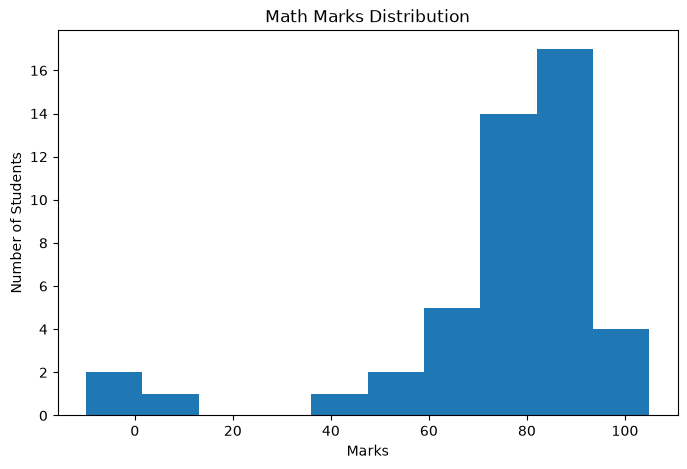

In [23]:
### Histogram – Marks Distribution

plt.figure(figsize=(8, 5))

plt.hist(df['math_marks'], bins=10)

plt.title('Math Marks Distribution')
plt.xlabel('Marks')
plt.ylabel('Number of Students')

plt.show()

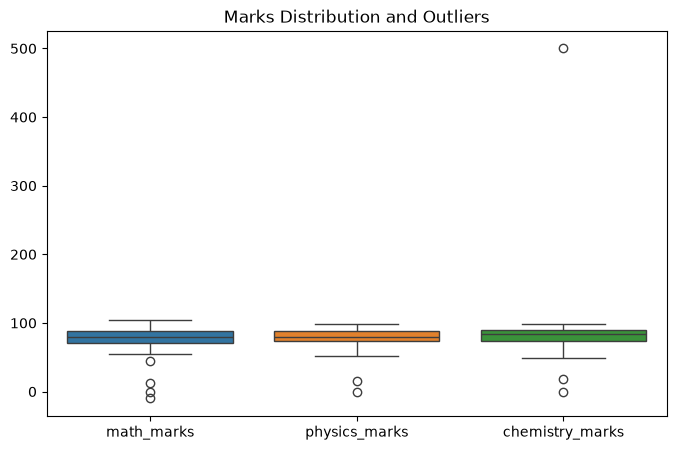

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[['math_marks', 'physics_marks', 'chemistry_marks']])

plt.title('Marks Distribution and Outliers')

plt.show()

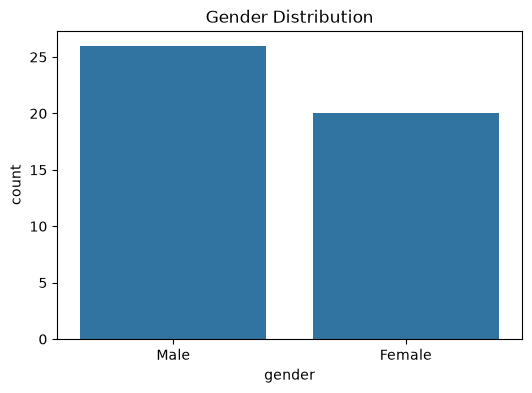

In [25]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='gender')

plt.title('Gender Distribution')

plt.show()

In [28]:
df.head(2)

,student_id,name,gender,age,department,math_marks,physics_marks,chemistry_marks,exam_date,city,email
0,1,Rahim,Male,20.0,CSE,85.0,78.0,92.0,2025-01-15,Dhaka,rahim@example.com
1,2,Karim,Male,22.0,CSE,76.0,81.0,88.0,2025-01-17,Dhaka,karim@example.com


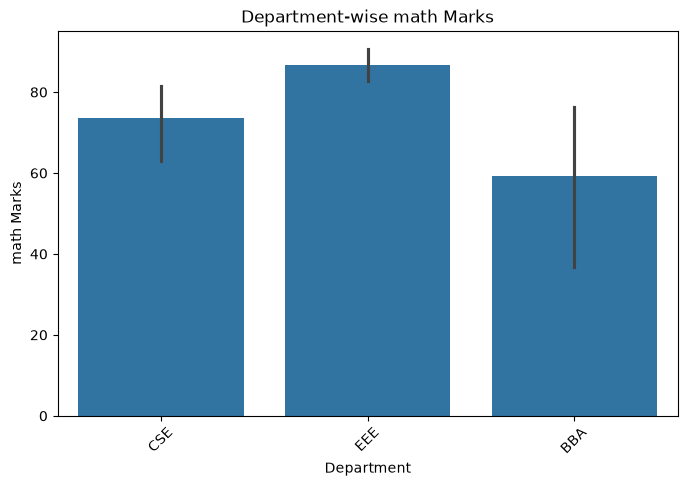

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='department', y='math_marks',)

plt.title('Department-wise math Marks')
plt.xlabel('Department')
plt.ylabel('math Marks')

plt.xticks(rotation=45)

plt.show()

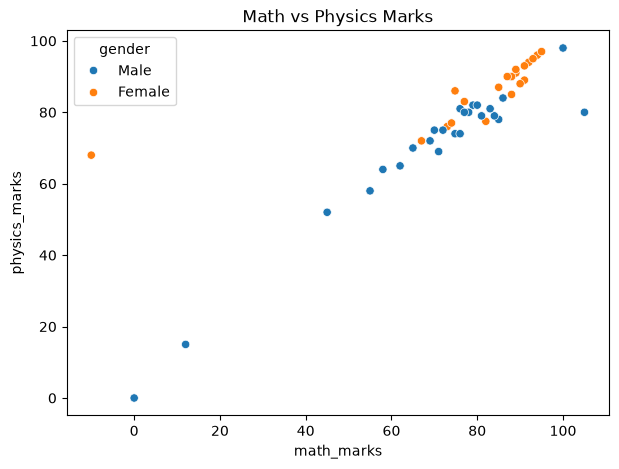

In [31]:
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x='math_marks', y='physics_marks', hue='gender')

plt.title('Math vs Physics Marks')

plt.show()

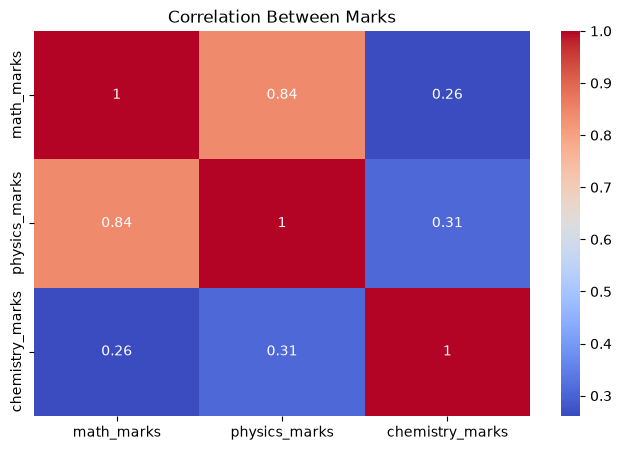

In [33]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[['math_marks', 'physics_marks', 'chemistry_marks',]].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Between Marks')

plt.show()

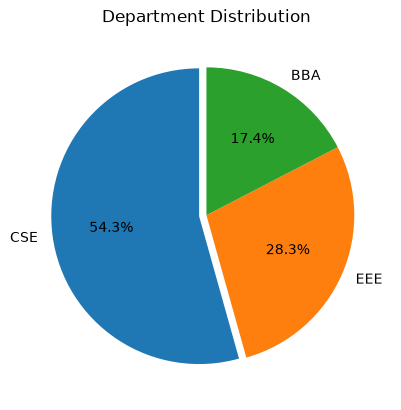

In [47]:
plt.pie(x=df['department'].value_counts(), labels=df['department'].unique(), autopct='%1.1f%%', startangle=90, explode=(0.05, 0, 0,), )

plt.title('Department Distribution')

plt.ylabel('')

plt.show()